**Medidas de Desempenho de Classificadores**

Prof. Fernando Vieira da Silva

A escolha do melhor modelo de classificação é uma tarefa de extrema importância para implantação de sistemas que utilizam machine learning em ambiente de produção. Como veremos a seguir, nem sempre a acurácia diz o que precisamos saber sobre o quanto o modelo se adequa a um problema específico. 

Além disso, deve-se considerar que modelos mais complexos podem demandar maior capacidade computacional, sendo assim mais custosos. Por isso, é importante comparar os modelos para entender se há diferença significativa que justifique a escolha por um modelo mais complexo.

Nesta aula vamos tomar como exemplo um **Sistema de classificação de evento de futebol, com base no texto da narração** (falta, cartão amarelo ou vermelho, gol, etc) https://www.kaggle.com/secareanualin/football-events

Vamos começar com a definição de acurácia.

**Acurácia**
Mede a diferença de um resultado obtido com o resultado esperado. 

Ex: Se para 1000 eventos do jogo o modelo prever 700 corretamente, sua acurácia é de 70%

Porém, suponha que, ainda no exemplo acima, todos os 30% dos casos de erro são cartões vermelhos. Se eu quiser que esse sistema identifique somente cartões vermelhos, quão bom meu modelo realmente é? Veremos outras formas para medir o desempenho

**Precisão**

Precisão: Dentre as amostras classificados como X, quantas realmente eram da classe X?

Ex:  
* Submeti 1000 eventos para meu classificador. 
* Ele retornou que 300 deles são do tipo chute a gol. 
* Desses 300, apenas 200 eram realmente chute a gol, os demais foram classificados incorretamente (falsos positivos)
* Logo, a **Precisão** do classificador para chute a gol é 66,6%

**Revocação (Recall)**
Revocação: Dentre as amostras existentes da classe X, quantas foram classificadas como a classe X?

Ex:
* Dentre os 1000 eventos que possuo, 400 são do tipo chute a gol.
* Submeti esses 400 eventos para meu classificador.
* O classificador indicou que 200 deles são do tipo chute a gol, os demais foram classificados incorretamente como outro tipo de evento (falsos negativos)
* Logo, a **Revocação** do classificador para chute a gol é 50%

<p><a href="https://commons.wikimedia.org/wiki/File:Precisionrecall.svg#/media/File:Precisionrecall.svg"><img src="https://upload.wikimedia.org/wikipedia/commons/thumb/2/26/Precisionrecall.svg/1200px-Precisionrecall.svg.png" alt="Precisionrecall.svg"></a><br>By <a href="//commons.wikimedia.org/wiki/User:Walber" title="User:Walber">Walber</a> - <span class="int-own-work" lang="en">Own work</span>, <a href="https://creativecommons.org/licenses/by-sa/4.0" title="Creative Commons Attribution-Share Alike 4.0">CC BY-SA 4.0</a>, <a href="https://commons.wikimedia.org/w/index.php?curid=36926283">Link</a></p>

**Que tipos de problemas a Precisão e a Revocação podem ser melhores medidas de desempenho do que a Acurácia?**

**F1-score (F-score ou F-measure)**

Trata-se da média harmônica entre Precisão e Revocação. Pode ser um indicador melhor do desempenho de um algoritmo do que a Acurácia, mas trata Precisão e Revocação com a mesma importância (o que nem sempre é verdadeiro).

**Exercício 1**
Avalie Acurácia, Precisão, Revocação e F1-Score de cada um dos 4 modelos disponíveis para classificação de eventos de um jogo de futebol, com base no texto da narração. O código abaixo mostra esses resultados para o modelo de regressão logística. Replique para os demais modelos disponíveis. Quais são suas conclusões?

Desafio: Ao invés de utilizar o classification_report, utilize a função f1_score e indique o melhor modelo para cada um dos tipos de evento disponíveis.

In [3]:
import pickle

from sklearn.metrics import classification_report
from nltk import pos_tag
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import string
from sklearn.metrics import f1_score

######## Funções Utilitárias para o modelo #################
stopwords_list = stopwords.words('english')

lemmatizer = WordNetLemmatizer()

from nltk.corpus import wordnet

from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer

def event_tokenizer(words):    
    #print("POS Tagging...\n")
    pos_tags = pos_tag(words)
     
    #print("Stopwords removal...\n")
    non_stopwords = [w for w in pos_tags if not w[0].lower() in stopwords_list]
     
    #print("Punctuation removal...\n")
    non_punctuation = [w for w in non_stopwords if not w[0] in string.punctuation]
     
    #print("Lemmatization...\n")
    lemmas = []
    for w in non_punctuation:
        if w[1].startswith('J'):
             pos = wordnet.ADJ
        elif w[1].startswith('V'):
             pos = wordnet.VERB
        elif w[1].startswith('N'):
             pos = wordnet.NOUN
        elif w[1].startswith('R'):
             pos = wordnet.ADV
        else:
             pos = wordnet.NOUN
         
        lemmas.append(lemmatizer.lemmatize(w[0], pos))

    #print("Done Tokenization!\n")
    return lemmas
    
class SVDDimSelect(object):
    def fit(self, X, y=None):      
        print("SVDDimSelect: Fitting to shape/2\n")         
        self.svd_transformer = TruncatedSVD(n_components=round(X.shape[1]/2))
        self.svd_transformer.fit(X)
        
        print("SVDDimSelect: Sorting cummulative variances\n")
        cummulative_variance = 0.0
        k = 0
        for var in sorted(self.svd_transformer.explained_variance_ratio_)[::-1]:
            cummulative_variance += var
            # I empirically decided to choose only the 20% of the components with 
            # most variance.
            if cummulative_variance >= 0.95:
                break
            else:
                k += 1
                
        
        print("SVDDimSelect: number of components = %d\n" % k)
        self.svd_transformer = TruncatedSVD(n_components=k)
        return self.svd_transformer.fit(X)
    
    def transform(self, X, Y=None):
        return self.svd_transformer.transform(X)

########################


In [4]:

# Carrega dataset de teste    
x_test_evt = pickle.load(open('../input/data-preparation/football_events_x_test.pkl', 'rb'))
y_test_evt = pickle.load(open('../input/data-preparation/football_events_y_test.pkl', 'rb'))

# Carregando modelo de Regressão Logística
model_event = pickle.load(open('../input/events-classifier-models/football_event_model_LOG-REGRESSION.pkl', 'rb'))

y_pred = model_event.predict(x_test_evt)

''' Cada coluna da matriz y_pred representa uma das categorias do evento, sendo:
Attempt, Corner, Foul, Yellow card, Second yellow card, Red card, Substitution, 
Free kick won, Offside, Hand ball, Penalty conceded, Key Pass, Failed through ball, Sending off '''

print(classification_report(y_test_evt, y_pred, target_names=['Attempt', 'Corner', 
                                                              'Foul', 'Yellow card', 
                                                              'Second yellow card', 
                                                              'Red card', 'Substitution', 
                                                              'Free kick won', 'Offside', 
                                                              'Hand ball', 'Penalty conceded', 
                                                              'Key Pass', 
                                                              'Failed through ball', 'Sending off']))

print(f1_score(y_test_evt, y_pred, average=None))
 

/opt/conda/lib/python3.6/site-packages/sklearn/base.py:251: UserWarning: Trying to unpickle estimator TfidfTransformer from version 0.20.1 when using version 0.20.2. This might lead to breaking code or invalid results. Use at your own risk.
  UserWarning)
/opt/conda/lib/python3.6/site-packages/sklearn/base.py:251: UserWarning: Trying to unpickle estimator TfidfVectorizer from version 0.20.1 when using version 0.20.2. This might lead to breaking code or invalid results. Use at your own risk.
  UserWarning)
/opt/conda/lib/python3.6/site-packages/sklearn/base.py:251: UserWarning: Trying to unpickle estimator LogisticRegression from version 0.20.1 when using version 0.20.2. This might lead to breaking code or invalid results. Use at your own risk.
  UserWarning)
/opt/conda/lib/python3.6/site-packages/sklearn/base.py:251: UserWarning: Trying to unpickle estimator OneVsRestClassifier from version 0.20.1 when using version 0.20.2. This might lead to breaking code or invalid results. Use at yo

                     precision    recall  f1-score   support

            Attempt       0.97      0.95      0.96      2171
             Corner       0.98      0.96      0.97      1015
               Foul       0.90      0.89      0.90      2824
        Yellow card       1.00      0.86      0.92       364
 Second yellow card       0.00      0.00      0.00         8
           Red card       0.88      0.69      0.77       465
       Substitution       0.99      1.00      1.00      2949
      Free kick won       0.98      0.57      0.72       476
            Offside       1.00      0.39      0.56        93
          Hand ball       0.00      0.00      0.00        10
   Penalty conceded       0.77      0.78      0.78      1479
           Key Pass       0.98      0.57      0.72       476
Failed through ball       0.00      0.00      0.00        16
        Sending off       0.00      0.00      0.00         8

          micro avg       0.94      0.88      0.91     12354
          macro avg   

/opt/conda/lib/python3.6/site-packages/sklearn/metrics/classification.py:1143: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples.
  'precision', 'predicted', average, warn_for)
/opt/conda/lib/python3.6/site-packages/sklearn/metrics/classification.py:1143: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels.
  'precision', 'predicted', average, warn_for)
/opt/conda/lib/python3.6/site-packages/sklearn/metrics/classification.py:1143: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no predicted samples.
  'precision', 'predicted', average, warn_for)


In [ ]:

# Carrega dataset de teste    
x_test_evt = pickle.load(open('../input/data-preparation/football_events_x_test.pkl', 'rb'))
y_test_evt = pickle.load(open('../input/data-preparation/football_events_y_test.pkl', 'rb'))

# Carregando modelo de Regressão Logística
model_event = pickle.load(open('../input/events-classifier-models/football_event_model_RANDOM-FOREST.pkl', 'rb'))

y_pred = model_event.predict(x_test_evt)

''' Cada coluna da matriz y_pred representa uma das categorias do evento, sendo:
Attempt, Corner, Foul, Yellow card, Second yellow card, Red card, Substitution, 
Free kick won, Offside, Hand ball, Penalty conceded, Key Pass, Failed through ball, Sending off '''

print(classification_report(y_test_evt, y_pred, target_names=['Attempt', 'Corner', 
                                                              'Foul', 'Yellow card', 
                                                              'Second yellow card', 
                                                              'Red card', 'Substitution', 
                                                              'Free kick won', 'Offside', 
                                                              'Hand ball', 'Penalty conceded', 
                                                              'Key Pass', 
                                                              'Failed through ball', 'Sending off']))

print(f1_score(y_test_evt, y_pred, average=None))
 

In [ ]:

# Carrega dataset de teste    
x_test_evt = pickle.load(open('../input/data-preparation/football_events_x_test.pkl', 'rb'))
y_test_evt = pickle.load(open('../input/data-preparation/football_events_y_test.pkl', 'rb'))

# Carregando modelo de Regressão Logística
model_event = pickle.load(open('../input/events-classifier-models/football_event_model_SVC-LINEAR.pkl', 'rb'))

y_pred = model_event.predict(x_test_evt)

''' Cada coluna da matriz y_pred representa uma das categorias do evento, sendo:
Attempt, Corner, Foul, Yellow card, Second yellow card, Red card, Substitution, 
Free kick won, Offside, Hand ball, Penalty conceded, Key Pass, Failed through ball, Sending off '''

print(classification_report(y_test_evt, y_pred, target_names=['Attempt', 'Corner', 
                                                              'Foul', 'Yellow card', 
                                                              'Second yellow card', 
                                                              'Red card', 'Substitution', 
                                                              'Free kick won', 'Offside', 
                                                              'Hand ball', 'Penalty conceded', 
                                                              'Key Pass', 
                                                              'Failed through ball', 'Sending off']))

print(f1_score(y_test_evt, y_pred, average=None))
 

In [ ]:

# Carrega dataset de teste    
x_test_evt = pickle.load(open('../input/data-preparation/football_events_x_test.pkl', 'rb'))
y_test_evt = pickle.load(open('../input/data-preparation/football_events_y_test.pkl', 'rb'))

# Carregando modelo de Regressão Logística
model_event = pickle.load(open('../input/events-classifier-models/football_event_model_SVC-RBF.pkl', 'rb'))

y_pred = model_event.predict(x_test_evt)

''' Cada coluna da matriz y_pred representa uma das categorias do evento, sendo:
Attempt, Corner, Foul, Yellow card, Second yellow card, Red card, Substitution, 
Free kick won, Offside, Hand ball, Penalty conceded, Key Pass, Failed through ball, Sending off '''

print(classification_report(y_test_evt, y_pred, target_names=['Attempt', 'Corner', 
                                                              'Foul', 'Yellow card', 
                                                              'Second yellow card', 
                                                              'Red card', 'Substitution', 
                                                              'Free kick won', 'Offside', 
                                                              'Hand ball', 'Penalty conceded', 
                                                              'Key Pass', 
                                                              'Failed through ball', 'Sending off']))

print(f1_score(y_test_evt, y_pred, average=None))
 

**Curva ROC (Receiving Operating Characteristic)**

Um modelo classificador binário geralmente retorna o nível de confiança que o resultado retornado realmente seja de uma determinada classe - variando de 0 a 1,0. Mas a partir de qual nível de confiança pode-se obter o melhor resultado do classificador? Devemos simplesmente considerar que se o nível de confiança for > 0.50 então a classe é 1, senão a classe é 0?

Para obter melhores resultados, podemos analisar esse threshould usando uma curva ROC. Essa curva nos dá o número de positivos verdadeiros e falsos positivos para cada threshould, em relação ao que seria um classificador aleatório, como vemos na imagem abaixo.



In [5]:
probas = model_event.predict_proba(x_test_evt)
print(probas)

[[1.32577249e-03 8.79892371e-03 7.79049240e-03 ... 2.91343577e-04
  7.51510370e-04 4.47711257e-04]
 [5.14723208e-06 1.46015055e-06 9.89267138e-01 ... 3.21450590e-03
  4.07561149e-04 1.90944588e-04]
 [9.48328712e-04 2.40798229e-04 1.59276211e-01 ... 3.90340279e-04
  5.82329674e-04 2.37790296e-04]
 ...
 [3.20109447e-05 2.78194175e-02 2.87738419e-01 ... 4.59597450e-04
  2.13342602e-04 1.63275751e-04]
 [3.00837433e-04 1.52963943e-04 7.08969912e-03 ... 3.40588969e-03
  5.48830926e-04 1.59055372e-04]
 [9.95701728e-01 6.72450746e-03 3.44251199e-03 ... 4.20454207e-03
  2.97978592e-04 4.85617871e-04]]


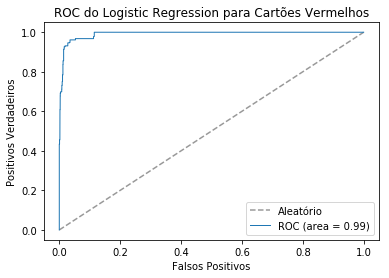

In [6]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Cartões vermelhos estão na coluna 5
RED_CARD_INDEX = 5
fpr, tpr, thresholds = roc_curve(y_test_evt[:,RED_CARD_INDEX], probas[:,RED_CARD_INDEX])
roc_auc = auc(fpr, tpr)

plt.plot([0, 1], [0, 1], '--', color=(0.6, 0.6, 0.6), label='Aleatório')
plt.plot(fpr, tpr, lw=1, label='ROC (area = %0.2f)' % roc_auc)

plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel('Falsos Positivos')
plt.ylabel('Positivos Verdadeiros')
plt.title('ROC do Logistic Regression para Cartões Vermelhos')
plt.legend(loc="lower right")
plt.show()


**Exercício 2**
Plote a curva ROC dos classificadores Logistic Regression e Random Forest para os eventos de cartão vermelho e penalty. Calcule a área das curvas. Quais é o melhor classificador e o melhor modelo para essas categorias de eventos?

**Matriz de Confusão**

A matriz de confusão nos permite observar os casos de erro. Para cada uma das categorias, podemos ver como as amostras classificadas incorretamente são classificadas pelo modelo. Em outras palavras, tomando o exemplo de classificador de eventos de futebol, em que categorias os cartões vermelhos errados foram classificados?

In [ ]:
y_test_evt_multi = []
y_pred_multi = []

for y_sample, pred_sample in zip(y_test_evt, y_pred):    
    for i in range(len(y_sample)):
        if y_sample[i] == 1:
            y_test_evt_multi.append(i)
            break
    check = False
    for i in range(len(pred_sample)):         
        if pred_sample[i] == 1:
            y_pred_multi.append(i)
            check = True
            break
    if not check:
        y_pred_multi.append(len(pred_sample))
            

In [ ]:
from sklearn.metrics import confusion_matrix
cnf_matrix = confusion_matrix(y_test_evt_multi, y_pred_multi)
print(cnf_matrix)

In [ ]:
import itertools
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues,
                         print_numbers=False):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    if print_numbers:
        for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
            plt.text(j, i, format(cm[i, j], fmt),
                     horizontalalignment="center",
                     color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()

In [ ]:
import numpy as np
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=['Attempt', 'Corner', 
                                                              'Foul', 'Yellow card', 
                                                              'Second yellow card', 
                                                              'Red card', 'Substitution', 
                                                              'Free kick won', 'Offside', 
                                                              'Hand ball', 'Penalty conceded', 
                                                              'Key Pass', 
                                                              'Failed through ball', 'Sending off'],
                      title='Confusion matrix sem normalização')

plt.figure()
plot_confusion_matrix(cnf_matrix, classes=['Attempt', 'Corner', 
                                                              'Foul', 'Yellow card', 
                                                              'Second yellow card', 
                                                              'Red card', 'Substitution', 
                                                              'Free kick won', 'Offside', 
                                                              'Hand ball', 'Penalty conceded', 
                                                              'Key Pass', 
                                                              'Failed through ball', 'Sending off'],
                      title='Confusion matrix com normalização', normalize=True)

plt.show()

Perceba porém que há um espaço em branco no gráfico. Isso ocorre porque esse trata-se de um problema de Multilabel que tratamos como Multiclass para simplificar o exemplo didático. Em outras palavras, alguns samples eram classificados como mais de uma categoria (ex: Atempt e Key Pass; e Foul e Penalty conceded). Em casos como esses, temos a opção de plotar uma matriz de confusão multilabel. Como essa função ainda está em desenvolvimento na biblioteca do sklearn (Dezembro/2018), copiamos aqui o código retirado da versão dev. 

Observe que essa matriz só exibe o número de positivos reais, falsos positivos, falsos reais e falsos negativos para cada categoria.

In [ ]:
## Código copiado da versão de desenvolvimento do sklearn ##

import numpy as np
from sklearn.utils import check_consistent_length
from sklearn.utils.sparsefuncs import count_nonzero
from sklearn.utils.multiclass import type_of_target, unique_labels
from scipy.sparse import csr_matrix

def _check_targets(y_true, y_pred):
    """Check that y_true and y_pred belong to the same classification task
    This converts multiclass or binary types to a common shape, and raises a
    ValueError for a mix of multilabel and multiclass targets, a mix of
    multilabel formats, for the presence of continuous-valued or multioutput
    targets, or for targets of different lengths.
    Column vectors are squeezed to 1d, while multilabel formats are returned
    as CSR sparse label indicators.
    Parameters
    ----------
    y_true : array-like
    y_pred : array-like
    Returns
    -------
    type_true : one of {'multilabel-indicator', 'multiclass', 'binary'}
        The type of the true target data, as output by
        ``utils.multiclass.type_of_target``
    y_true : array or indicator matrix
    y_pred : array or indicator matrix
    """
    check_consistent_length(y_true, y_pred)
    type_true = type_of_target(y_true)
    type_pred = type_of_target(y_pred)

    y_type = set([type_true, type_pred])
    if y_type == set(["binary", "multiclass"]):
        y_type = set(["multiclass"])

    if len(y_type) > 1:
        raise ValueError("Classification metrics can't handle a mix of {0} "
                         "and {1} targets".format(type_true, type_pred))

    # We can't have more than one value on y_type => The set is no more needed
    y_type = y_type.pop()

    # No metrics support "multiclass-multioutput" format
    if (y_type not in ["binary", "multiclass", "multilabel-indicator"]):
        raise ValueError("{0} is not supported".format(y_type))

    if y_type in ["binary", "multiclass"]:
        y_true = column_or_1d(y_true)
        y_pred = column_or_1d(y_pred)
        if y_type == "binary":
            unique_values = np.union1d(y_true, y_pred)
            if len(unique_values) > 2:
                y_type = "multiclass"

    if y_type.startswith('multilabel'):
        y_true = csr_matrix(y_true)
        y_pred = csr_matrix(y_pred)
        y_type = 'multilabel-indicator'

    return y_type, y_true, y_pred

def multilabel_confusion_matrix(y_true, y_pred, sample_weight=None,
                                labels=None, samplewise=False):
    """Compute a confusion matrix for each class or sample
    .. versionadded:: 0.21
    Compute class-wise (default) or sample-wise (samplewise=True) multilabel
    confusion matrix to evaluate the accuracy of a classification, and output
    confusion matrices for each class or sample.
    In multilabel confusion matrix :math:`MCM`, the count of true negatives
    is :math:`MCM_{:,0,0}`, false negatives is :math:`MCM_{:,1,0}`,
    true positives is :math:`MCM_{:,1,1}` and false positives is
    :math:`MCM_{:,0,1}`.
    Multiclass data will be treated as if binarized under a one-vs-rest
    transformation. Returned confusion matrices will be in the order of
    sorted unique labels in the union of (y_true, y_pred).
    Read more in the :ref:`User Guide <multilabel_confusion_matrix>`.
    Parameters
    ----------
    y_true : 1d array-like, or label indicator array / sparse matrix
        of shape (n_samples, n_outputs) or (n_samples,)
        Ground truth (correct) target values.
    y_pred : 1d array-like, or label indicator array / sparse matrix
        of shape (n_samples, n_outputs) or (n_samples,)
        Estimated targets as returned by a classifier
    sample_weight : array-like of shape = (n_samples,), optional
        Sample weights
    labels : array-like
        A list of classes or column indices to select some (or to force
        inclusion of classes absent from the data)
    samplewise : bool, default=False
        In the multilabel case, this calculates a confusion matrix per sample
    Returns
    -------
    multi_confusion : array, shape (n_outputs, 2, 2)
        A 2x2 confusion matrix corresponding to each output in the input.
        When calculating class-wise multi_confusion (default), then
        n_outputs = n_labels; when calculating sample-wise multi_confusion
        (samplewise=True), n_outputs = n_samples. If ``labels`` is defined,
        the results will be returned in the order specified in ``labels``,
        otherwise the results will be returned in sorted order by default.
    See also
    --------
    confusion_matrix
    Notes
    -----
    The multilabel_confusion_matrix calculates class-wise or sample-wise
    multilabel confusion matrices, and in multiclass tasks, labels are
    binarized under a one-vs-rest way; while confusion_matrix calculates
    one confusion matrix for confusion between every two classes.
    Examples
    --------
    Multilabel-indicator case:
    >>> import numpy as np
    >>> from sklearn.metrics import multilabel_confusion_matrix
    >>> y_true = np.array([[1, 0, 1],
    ...                    [0, 1, 0]])
    >>> y_pred = np.array([[1, 0, 0],
    ...                    [0, 1, 1]])
    >>> multilabel_confusion_matrix(y_true, y_pred)
    array([[[1, 0],
            [0, 1]],
    <BLANKLINE>
           [[1, 0],
            [0, 1]],
    <BLANKLINE>
           [[0, 1],
            [1, 0]]])
    Multiclass case:
    >>> y_true = ["cat", "ant", "cat", "cat", "ant", "bird"]
    >>> y_pred = ["ant", "ant", "cat", "cat", "ant", "cat"]
    >>> multilabel_confusion_matrix(y_true, y_pred,
    ...                             labels=["ant", "bird", "cat"])
    array([[[3, 1],
            [0, 2]],
    <BLANKLINE>
           [[5, 0],
            [1, 0]],
    <BLANKLINE>
           [[2, 1],
            [1, 2]]])
    """
    y_type, y_true, y_pred = _check_targets(y_true, y_pred)
    if sample_weight is not None:
        sample_weight = column_or_1d(sample_weight)
    check_consistent_length(y_true, y_pred, sample_weight)

    if y_type not in ("binary", "multiclass", "multilabel-indicator"):
        raise ValueError("%s is not supported" % y_type)

    present_labels = unique_labels(y_true, y_pred)
    if labels is None:
        labels = present_labels
        n_labels = None
    else:
        n_labels = len(labels)
        labels = np.hstack([labels, np.setdiff1d(present_labels, labels,
                                                 assume_unique=True)])

    if y_true.ndim == 1:
        if samplewise:
            raise ValueError("Samplewise metrics are not available outside of "
                             "multilabel classification.")

        le = LabelEncoder()
        le.fit(labels)
        y_true = le.transform(y_true)
        y_pred = le.transform(y_pred)
        sorted_labels = le.classes_

        # labels are now from 0 to len(labels) - 1 -> use bincount
        tp = y_true == y_pred
        tp_bins = y_true[tp]
        if sample_weight is not None:
            tp_bins_weights = np.asarray(sample_weight)[tp]
        else:
            tp_bins_weights = None

        if len(tp_bins):
            tp_sum = np.bincount(tp_bins, weights=tp_bins_weights,
                                 minlength=len(labels))
        else:
            # Pathological case
            true_sum = pred_sum = tp_sum = np.zeros(len(labels))
        if len(y_pred):
            pred_sum = np.bincount(y_pred, weights=sample_weight,
                                   minlength=len(labels))
        if len(y_true):
            true_sum = np.bincount(y_true, weights=sample_weight,
                                   minlength=len(labels))

        # Retain only selected labels
        indices = np.searchsorted(sorted_labels, labels[:n_labels])
        tp_sum = tp_sum[indices]
        true_sum = true_sum[indices]
        pred_sum = pred_sum[indices]

    else:
        sum_axis = 1 if samplewise else 0

        # All labels are index integers for multilabel.
        # Select labels:
        if not np.array_equal(labels, present_labels):
            if np.max(labels) > np.max(present_labels):
                raise ValueError('All labels must be in [0, n labels) for '
                                 'multilabel targets. '
                                 'Got %d > %d' %
                                 (np.max(labels), np.max(present_labels)))
            if np.min(labels) < 0:
                raise ValueError('All labels must be in [0, n labels) for '
                                 'multilabel targets. '
                                 'Got %d < 0' % np.min(labels))

        if n_labels is not None:
            y_true = y_true[:, labels[:n_labels]]
            y_pred = y_pred[:, labels[:n_labels]]

        # calculate weighted counts
        true_and_pred = y_true.multiply(y_pred)
        tp_sum = count_nonzero(true_and_pred, axis=sum_axis,
                               sample_weight=sample_weight)
        pred_sum = count_nonzero(y_pred, axis=sum_axis,
                                 sample_weight=sample_weight)
        true_sum = count_nonzero(y_true, axis=sum_axis,
                                 sample_weight=sample_weight)

    fp = pred_sum - tp_sum
    fn = true_sum - tp_sum
    tp = tp_sum

    if sample_weight is not None and samplewise:
        sample_weight = np.array(sample_weight)
        tp = np.array(tp)
        fp = np.array(fp)
        fn = np.array(fn)
        tn = sample_weight * y_true.shape[1] - tp - fp - fn
    elif sample_weight is not None:
        tn = sum(sample_weight) - tp - fp - fn
    elif samplewise:
        tn = y_true.shape[1] - tp - fp - fn
    else:
        tn = y_true.shape[0] - tp - fp - fn

    return np.array([tn, fp, fn, tp]).T.reshape(-1, 2, 2)

In [ ]:
# from sklearn.metrics import multilabel_confusion_matrix

multilabel_confusion_matrix(y_test_evt, y_pred)

**Exercício 3**: Plote a matriz de confusão resultante dos demais modelos. Para simplificar, utilize o estilo multiclass.

**Comparando resultados usando testes estatísticos**

Diversos algoritmos podem ser utilizados para resolver problemas de classificação. Porém, algoritmos mais complexos podem apresentar performance computacional maior. Isso implica em: 1) maior tempo gasto para classificação e 2) mais recursos computacionais gastos -- e maior custo financeiro.

Mas será que algoritmos mais complexos são tão melhores a ponto de valer a pena utilizá-los? Vamos utilizar testes estatísticos para verificar se os resultados são melhores e estatisticamente significativos.

Para comparar dois algoritmos, vamos rodá-los diversas vezes e obter a média dos resultados de cada um deles. Se as médias vierem de populações diferentes, 
então chegamos a conclusão que os resultados são diferentes de forma estatisticamente significativa.

Em outras palavras, nossa hipótese é:

H0 - A média dos resultados vem de uma mesma população.

Se a hipótese H0 for REJEITADA com p-value <= 0.05, então nós concluímos que as médias de resultados dos dois algoritmos vêm de populações diferentes, ou seja,
os resultados são estatísticamente diferentes.

Vamos começar dividindo aleatoriamente nosso dataset de teste em 30 partes iguais:


In [ ]:
num_parts = 30

test_sets_x = np.array_split(x_test_evt, num_parts)
test_sets_y = np.array_split(y_test_evt, num_parts)

Agora vamos testar nossos dois modelos em ambos os datasets. Vamos testar o Logistic Regression e o Random Forest.


In [ ]:
model_event_rf = pickle.load(open('../input/events-classifier-models/football_event_model_RANDOM-FOREST.pkl', 'rb'))

test_results_lr = []
test_results_rf = []

for i in range(num_parts):
    y_pred_part = model_event.predict(test_sets_x[i])
    test_results_lr.append(f1_score(test_sets_y[i], y_pred_part, average='weighted'))

    y_pred_part = model_event_rf.predict(test_sets_x[i])
    test_results_rf.append(f1_score(test_sets_y[i], y_pred_part, average='weighted'))


Antes de prosseguir com o teste estatístico, precisamos verificar se a distribuição dos resultados é normal e se os resultados dos dois algoritmos
possuem a mesma variância, para podermos utilizar o teste t-Student. Vamos usar os testes do scipy para verificar isso.


In [ ]:
from pandas import DataFrame

test_results_pd = DataFrame()
test_results_pd['lr'] = test_results_lr
test_results_pd['rf'] = test_results_rf

print(test_results_pd.describe())
print(test_results_pd.var)

from scipy.stats import normaltest

value, p = normaltest(test_results_lr)

if p >= 0.05:
    print("Resultados de Logistic Regression provavelmente seguem uma distribuição normal")
else:
    print("Resultados de Logistic Regression provavelmente NÃO seguem uma distribuição normal")
    
value, p = normaltest(test_results_rf)

if p >= 0.05:
    print("Resultados de Random Forest provavelmente seguem uma distribuição normal")
else:
    print("Resultados de Random Forest provavelmente NÃO seguem uma distribuição normal")


Se a distribuição fosse normal, poderíamos utilizar o teste t-Student (função ttest_ind do scipy) com equal_var=True em caso de mesma variância ou equal_var=False em caso de variâncias diferentes.

Como não é o caso dos resultados do Random Forest, vamos utilizar teste o Kolmogorov-Smirnov com a função ks_2samp() do scipy.

In [ ]:
from scipy.stats import ks_2samp

value, pvalue = ks_2samp(test_results_lr, test_results_rf)

if pvalue >= 0.05:
    print("Resultados dos modelos vem da mesma população e NÃO são estatisticamente diferentes")
else:
    print("Resultados dos modelos vem de populações diferentes e SÃO estatisticamente diferentes")


Agora vamos rever os resultados dos dois algoritmos:

In [ ]:
y_pred = model_event.predict(x_test_evt)

''' Cada coluna da matriz y_pred representa uma das categorias do evento, sendo:
Attempt, Corner, Foul, Yellow card, Second yellow card, Red card, Substitution, 
Free kick won, Offside, Hand ball, Penalty conceded, Key Pass, Failed through ball, Sending off '''

print(classification_report(y_test_evt, y_pred, target_names=['Attempt', 'Corner', 
                                                              'Foul', 'Yellow card', 
                                                              'Second yellow card', 
                                                              'Red card', 'Substitution', 
                                                              'Free kick won', 'Offside', 
                                                              'Hand ball', 'Penalty conceded', 
                                                              'Key Pass', 
                                                              'Failed through ball', 'Sending off']))


In [ ]:
y_pred = model_event_rf.predict(x_test_evt)

''' Cada coluna da matriz y_pred representa uma das categorias do evento, sendo:
Attempt, Corner, Foul, Yellow card, Second yellow card, Red card, Substitution, 
Free kick won, Offside, Hand ball, Penalty conceded, Key Pass, Failed through ball, Sending off '''

print(classification_report(y_test_evt, y_pred, target_names=['Attempt', 'Corner', 
                                                              'Foul', 'Yellow card', 
                                                              'Second yellow card', 
                                                              'Red card', 'Substitution', 
                                                              'Free kick won', 'Offside', 
                                                              'Hand ball', 'Penalty conceded', 
                                                              'Key Pass', 
                                                              'Failed through ball', 'Sending off']))
